In [1]:
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr
import pyremo as pr
import cmaps
import glob
#from REMO2020_mod import  open_mfdataset, domainclass, plotclass, remo_plotter_2mods
import os
from openpyxl import load_workbook
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
import matplotlib.patches as mpatches
from REMO2020TEB_mod import flip, modelclass_cities, open_prepare_dwd, prepare_remo_to_umask_seas
os.environ['PATH'] = '/work/ch0636/g300096/Python/envs/kernelR2020TEB/bin:' + os.environ['PATH']

/work/ch0636/g300096/Python/envs/kernelR2020TEB/lib/python3.10/site-packages/pyremo/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
# create variable info class for measurements
class dwdclass:
    def __init__(self,station,station_id):
        self.station = station
        self.station_id = station_id
        self.data = []

In [3]:
# Init dwdclass
dwd_data =[] # init
#
dwd_data.append(dwdclass("Hamburg","15973"))
dwd_data.append(dwdclass("Hannover","15811"))
dwd_data.append(dwdclass("Berlin","399"))

In [4]:
# give figure path
figpath = './figures/'

In [5]:
# Give the quantiles to be calculated (must inlcude 0.5)
quantiles = np.array([0.05,0.25,0.5,0.75,0.95])

In [6]:
# if we want to replace median with mean
lreplace_median=True

In [7]:
# read in REMO hourly data
remo_datap = "/work/ch0636/g300096/results/TEB/post-processed"

In [8]:
# Open dwd datasets
dwd_dpath = '/work/ch0636/g300096/data/TEB_analysis/station_data/'
for stat in dwd_data:
    stat.data = open_prepare_dwd(dwd_dpath+f'{stat.station}/',f'produkt_air_temperature_{stat.station_id}_akt','LUFTTEMPERATUR',2020,quantiles,lreplace_median,addc=273.15)

In [9]:
# define the runs to be analysed
modelruns =[] # init

# 
modelruns.append(modelclass_cities("036047","REMO2020 TEB","ECOSG_LCZ",'b-','0.0275'))
modelruns.append(modelclass_cities("036048","REMO2020 TEB iMOVE","LANDMATE",'r-','0.0275'))
modelruns.append(modelclass_cities("036049","REMO2020","GLCC",'c-','0.0275'))
modelruns.append(modelclass_cities("036043","REMO2020 TEB","ECOSG_LCZ",'b--','0.11'))
modelruns.append(modelclass_cities("036044","REMO2020 TEB iMOVE","LANDMATE",'r--','0.11'))
modelruns.append(modelclass_cities("036041","REMO2020","GLCC",'c--','0.11'))

In [10]:
## read in remo data and do masking
varname = "TEMP2"
for obj in modelruns:
    # open remo data
    remo_data = pr.parse_dates(xr.open_dataset(remo_datap+"/"+obj.userexp+"_postpro_1h_2020.nc"))
    # create initial xarray dataset
    obj.vardata = xr.Dataset()
    # loop over stations
    for stat in dwd_data:
        # read in mask file (depends on the resolution and station)
        if (obj.reso == '0.0275'):
            urb_rur_remo_mask = xr.open_dataset(f"./data_in/model_data/REMO_static/urmask_{stat.station}-ALPX-3_urclim_masks_fx.nc")
        elif (obj.reso == '0.11'):
            urb_rur_remo_mask = xr.open_dataset(f"./data_in/model_data/REMO_static/urmask_{stat.station}-EUR-11_urclim_masks_fx.nc")
        # merge remo data and the mask
        merged_data = xr.merge([remo_data,urb_rur_remo_mask[obj.maskname]],compat="override", join="override")
        # filter the data based on the mask
        stat_data = merged_data[varname].where(merged_data[obj.maskname] > 0.5,drop=True)
        # create weight and make a mean
        weight = np.cos(np.deg2rad(stat_data.rlat))
        rawdata = stat_data.weighted(weight).mean(dim=("rlat", "rlon")).squeeze().compute()
        # Shift time by 30 minutes backwards (REMO specific)
        rawdata = rawdata.assign_coords(time=rawdata.time - pd.Timedelta('30min'))
        # add coordinates for seasons and hours
        rawdata = rawdata.assign_coords(season=rawdata.time.dt.season,hour=rawdata.time.dt.hour)
        #
        final_data = rawdata.groupby(["season", "hour"]).quantile(quantiles, dim='time')
        if (lreplace_median):
            final_data.loc[dict(quantile=0.5)] = rawdata.groupby(["season", "hour"]).mean("time") # mask is 1.0
        #
        obj.vardata = obj.vardata.assign({stat.station:final_data.compute()})

In [11]:
# Define the order of seasons to be used (also when plotting)
seasons = ["DJF","MAM","JJA","SON"]

In [12]:
# select plotted quantiles for shading (and 1-q)
ploquan = [0.05,0.25]

In [13]:
# Reset and set rcParams
mpl.rcParams.update(mpl.rcParamsDefault)
#plt.rcParams["figure.figsize"] = (25, 25)
plt.rcParams["figure.subplot.wspace"] = 0.3
plt.rcParams["figure.subplot.hspace"] = 0.1
plt.rcParams["axes.titlesize"] = 26
plt.rcParams['axes.labelsize'] = 22
plt.rcParams["xtick.top"] = True
plt.rcParams["xtick.labeltop"] = False
plt.rcParams["xtick.bottom"] = True
plt.rcParams["xtick.labelbottom"] = True
plt.rcParams["ytick.left"] = True
plt.rcParams["ytick.labelleft"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["ytick.labelright"] = False
plt.rcParams['lines.markersize'] = 10
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
plt.rc('xtick', labelsize=24) 
plt.rc('ytick', labelsize=24) 
plt.rc('legend', fontsize=22)

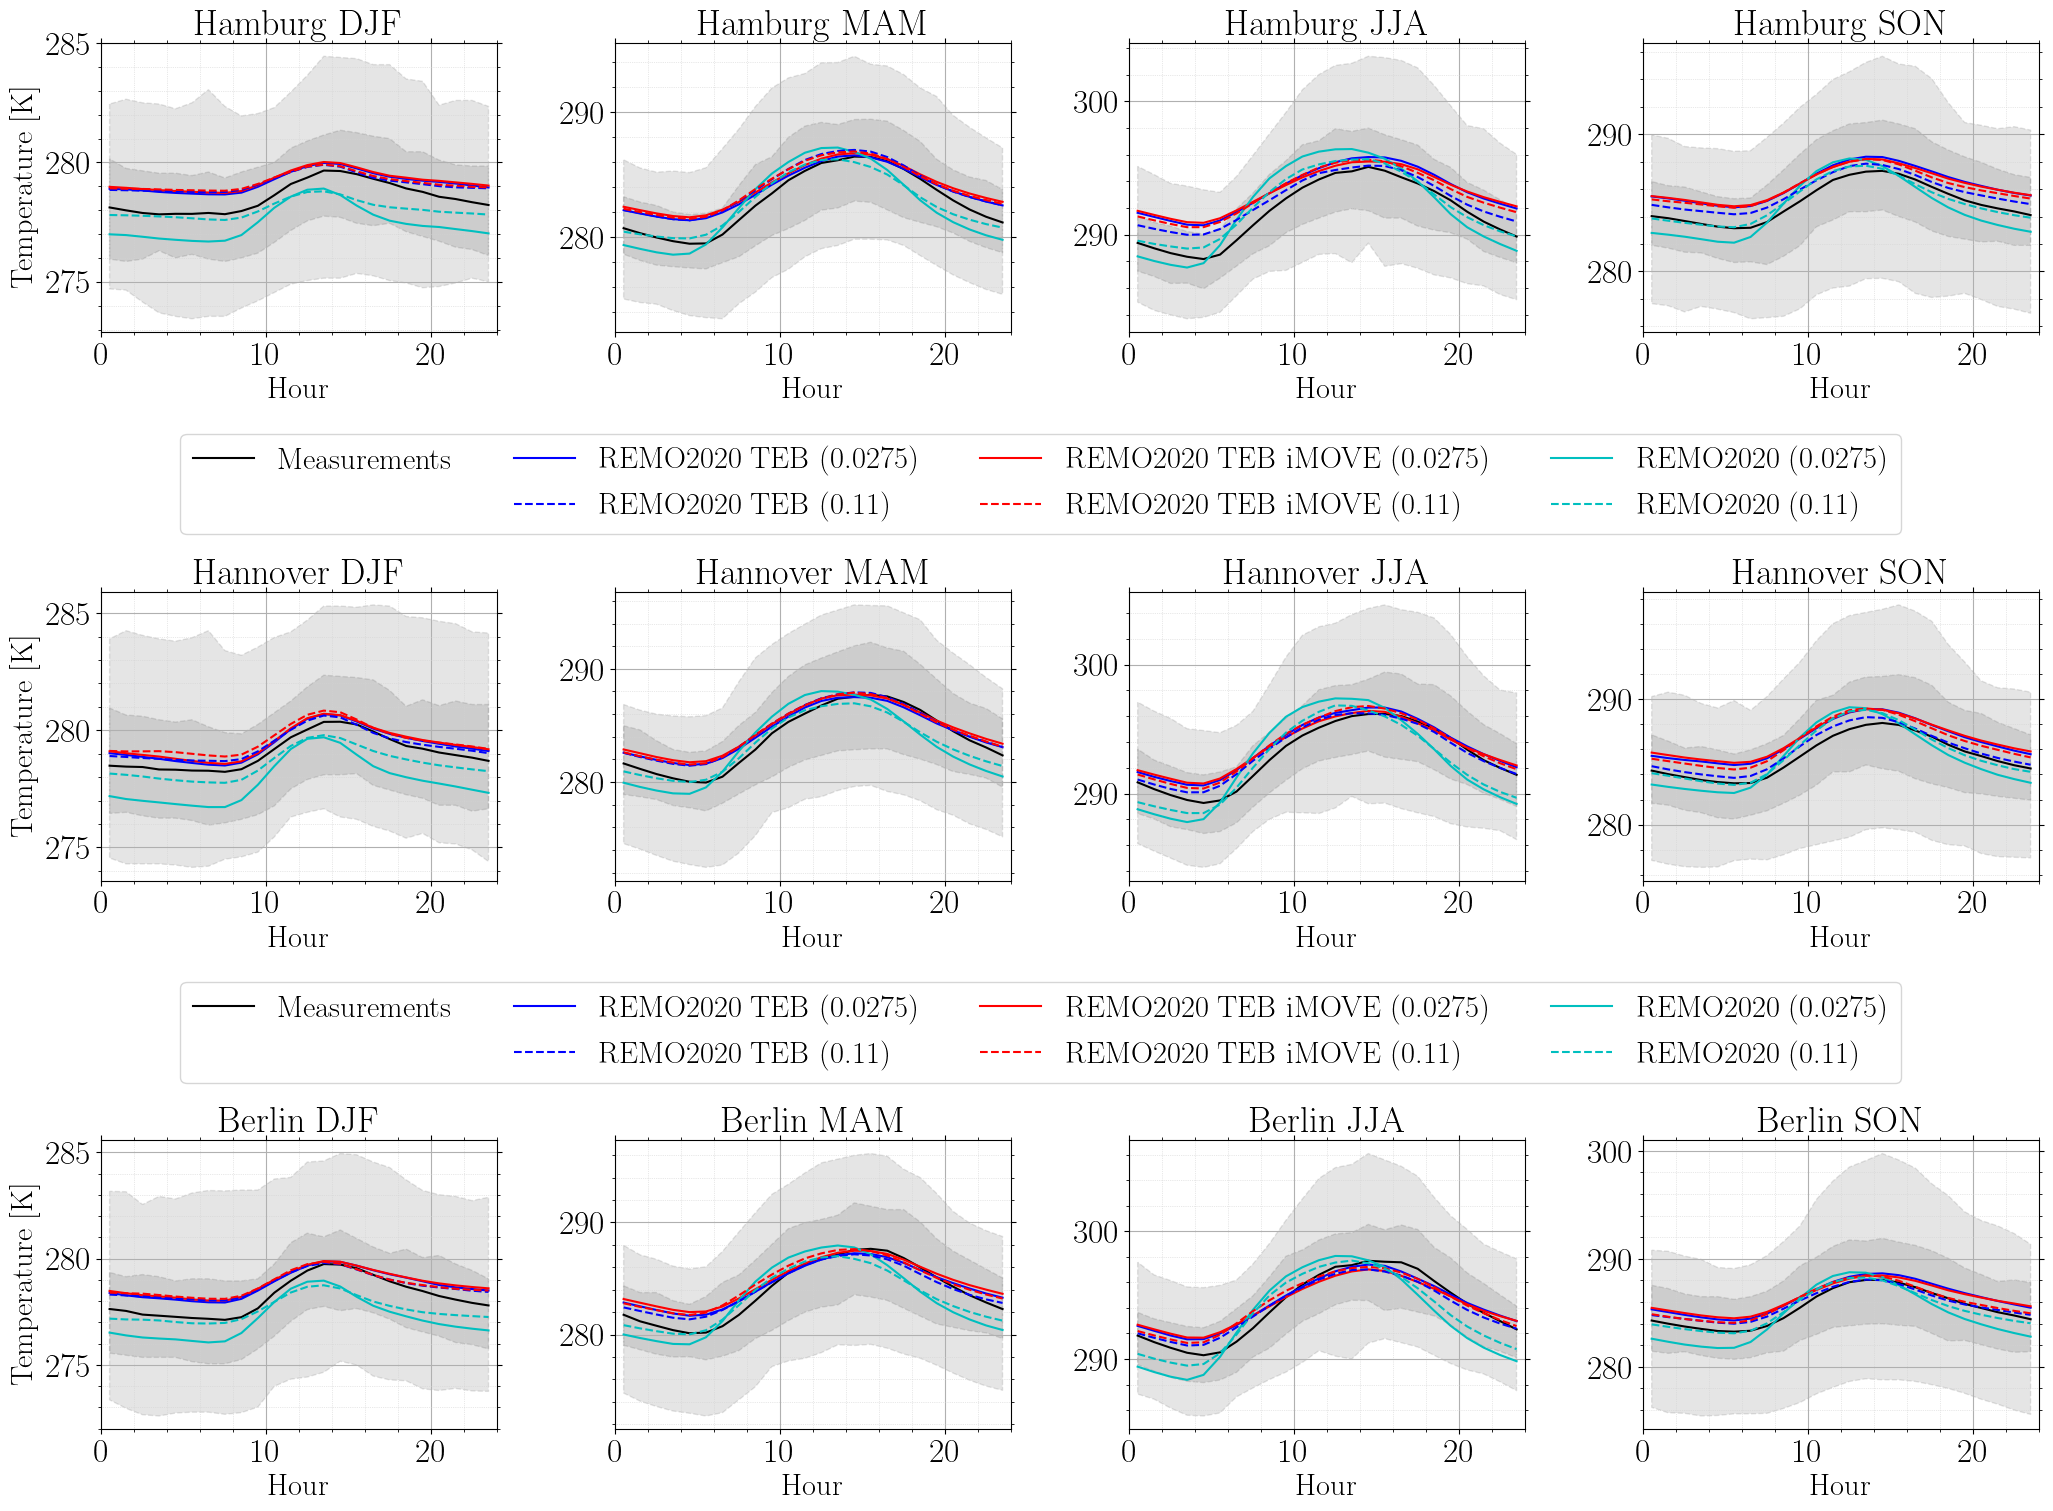

In [14]:
# plot specific configs
plt.rcParams["figure.subplot.hspace"] = 0.9
# Create subplots: station_count rows, 4 columns
fig, ax = plt.subplots(len(dwd_data), 4, figsize=(25, 18))
ax = ax.flatten()  # Flatten for easy indexing

# number of legend columns
ncol = 4
# some helper indexes
ind = 0
for seas in seasons:
    istat = 0
    for stat in dwd_data:
        ax[ind+istat].grid() # make grid and modify it
        ax[ind+istat].grid(which='minor', color='lightgrey', linestyle=':', linewidth=0.5)
        ax[ind+istat].minorticks_on() # use minor ticks
        # Urban plot (measurements)
        ax[ind+istat].plot(stat.data.hour.values+0.5,
                     stat.data.sel(season=seas).sel(quantile=0.5).values,
                     'k-', label="Measurements")
        for qq in ploquan:
            ax[ind+istat].fill_between(stat.data.hour.values+0.5,
                                stat.data.sel(season=seas).sel(quantile=qq).values, stat.data.sel(season=seas).sel(quantile=1.0-qq).values,
                                color='k', alpha=0.1, linewidth=1, linestyle = '--')
    
        for obj in modelruns:
            ax[ind+istat].plot(obj.vardata.hour.values+0.5,
                         obj.vardata[stat.station].sel(season=seas).sel(quantile=0.5).values,
                         obj.plstyle, label=obj.runame+" ("+obj.reso+")")

        ax[ind+istat].set_title(f"{stat.station} {seas}")
        ax[ind+istat].set_xlabel("Hour")
        ax[ind+istat].set_xlim([0,24])
        if seas == "DJF":
            ax[ind+istat].set_ylabel("Temperature [K]")
            if(istat != (len(dwd_data)-1)*len(seasons)):
                # flip and insert one empty string
                handles, labels = ax[ind+istat].get_legend_handles_labels()
                empty_patch = mpatches.Patch(color='none', label='') # create a patch with no color
                handles.insert(ncol, empty_patch)
                labels.insert(ncol,'')
                ax[ind+istat].legend(flip(handles, ncol), flip(labels, ncol),loc=(0.2, -0.7), ncol=ncol, frameon=True)
        # increas counter
        istat += len(seasons)
    # increas counter
    ind += 1

    
plt.savefig(figpath + f'DWD_seas_urmask_temp2.png', format="png", bbox_inches='tight', pad_inches=0)
plt.show()